# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma


In [1]:
OGRENCI_NO = "23120205072"

## 0. Kütüphaneler ve grafik ayarları

In [2]:
import os, glob, csv, json, copy, time
from dataclasses import dataclass, asdict
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets
from PIL import Image, ImageOps
from scipy import ndimage
import matplotlib.patches as patches
from IPython.display import Image as ShowImage, display

OUT = "sonuclar"
os.makedirs(OUT, exist_ok=True)
def goster(path):
    display(ShowImage(filename=path))

print("PyTorch", torch.__version__)

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False,
})


def plot_curves(hist, path, title):
    """Train/validation loss ve accuracy eğrileri (iki ayrı panel, tek eksen)."""
    ep = hist["epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, key, label in [(axes[0], "loss", "Loss (cross-entropy)"),
                           (axes[1], "acc", "Accuracy")]:
        ax.plot(ep, hist[f"train_{key}"], color=SERIES[0], marker="o", ms=4, label="Train")
        ax.plot(ep, hist[f"val_{key}"], color=SERIES[1], marker="o", ms=4, label="Validation")
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.legend()
    best = int(np.argmax(hist["val_acc"]))
    axes[1].annotate(f"en iyi val: {hist['val_acc'][best]:.4f}\n(epoch {ep[best]})",
                     xy=(ep[best], hist["val_acc"][best]), xytext=(0.45, 0.25),
                     textcoords="axes fraction", color=INK2, fontsize=9,
                     arrowprops=dict(arrowstyle="->", color=INK2))
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def plot_confusion(cm, path, title):
    cm = np.asarray(cm)
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    norm = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7.5,
                        color="white" if norm[i, j] > 0.5 else INK)
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xlabel("Tahmin edilen"); ax.set_ylabel("Gerçek")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label="Satır oranı")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def plot_misclassified(X, y_true, y_pred, conf, path, n=24):
    idx = np.where(y_true != y_pred)[0][:n]
    cols = 8
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.25, rows * 1.5))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i in zip(np.ravel(axes), idx):
        ax.imshow(X[i], cmap="gray")
        ax.set_title(f"G:{y_true[i]} T:{y_pred[i]}\n%{conf[i]*100:.0f}", fontsize=8,
                     fontweight="normal")
    fig.suptitle("Test kümesinde yanlış sınıflandırılan örnekler (G: gerçek, T: tahmin)",
                 fontweight="bold")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def plot_val_curves_groups(groups, histories, path):
    n = len(groups)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.6, rows * 3.5), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    for ax, (gname, names) in zip(axes.ravel(), groups.items()):
        for k, name in enumerate(names):
            h = histories[name]
            ax.plot(h["epoch"], h["val_acc"], color=SERIES[k], label=name)
        ax.set_title(gname)
        ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        lo = min(min(histories[nm]["val_acc"][1:] or histories[nm]["val_acc"]) for nm in names)
        ax.set_ylim(max(0.85, lo - 0.005), 0.99)
        ax.legend(fontsize=8)
    fig.suptitle("Deney 2 – hiperparametrelerin validation accuracy'ye etkisi",
                 fontweight="bold")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def plot_overfit(histories, names, path):
    fig, axes = plt.subplots(1, len(names), figsize=(4.4 * len(names), 3.6), sharey=True)
    for ax, name in zip(np.atleast_1d(axes), names):
        h = histories[name]
        ax.plot(h["epoch"], h["train_loss"], color=SERIES[0], label="Train")
        ax.plot(h["epoch"], h["val_loss"], color=SERIES[1], label="Validation")
        ax.set_title(name); ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Loss")
    fig.suptitle("Overfitting karşılaştırması: train vs validation loss", fontweight="bold")
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def plot_bar(names, values, path, title, xlabel, highlight=None):
    order = np.argsort(values)
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(names) + 1.2))
    vals = np.array(values)[order]
    labs = np.array(names)[order]
    colors = [SERIES[1] if l == highlight else SERIES[0] for l in labs]
    ax.barh(labs, vals, color=colors, height=0.62)
    lo = max(0.0, vals.min() - 0.01)
    ax.set_xlim(lo, min(1.0, vals.max() + 0.006))
    for i, v in enumerate(vals):
        ax.text(v + 0.0004, i, f"{v:.4f}", va="center", fontsize=8.5, color=INK)
    ax.set_xlabel(xlabel); ax.set_title(title)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)

PyTorch 2.11.0+cpu


## 1. Veri seti: train / validation / test ayrımı





train:  50000 görüntü, boyut (28, 28)
val  :  10000 görüntü, boyut (28, 28)
test :  10000 görüntü, boyut (28, 28)
Normalizasyon (train'den): mean = 0.1306, std = 0.3081


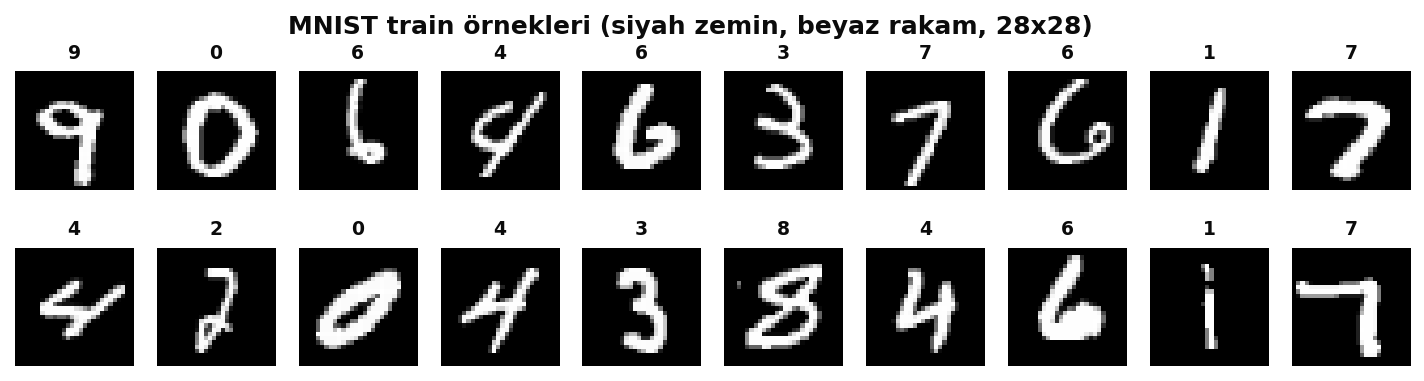

In [3]:
"""MNIST verisinin yüklenmesi ve train / validation / test ayrımı.

- Orijinal MNIST eğitim kümesi (60.000 görüntü) sabit bir seed ile
  50.000 TRAIN + 10.000 VALIDATION olarak ikiye bölünür.
- Orijinal MNIST test kümesi (10.000 görüntü) TEST olarak ayrı tutulup
  yalnızca eğitim bittikten sonra, son değerlendirmede bir kez kullanılacak.
- Normalizasyon istatistikleri (ortalama / standart sapma) SADECE train
  kümesinden hesaplanacak; böylece validation ve test bilgisi modele sızmayacak.
"""
import torch
from torchvision import datasets


def load_mnist(root="data", val_size=10_000, seed=42):
    train_full = datasets.MNIST(root, train=True, download=True)
    test_set = datasets.MNIST(root, train=False, download=True)

    X_full = train_full.data.float().div_(255.0)
    y_full = train_full.targets.clone()
    X_test = test_set.data.float().div_(255.0)
    y_test = test_set.targets.clone()

    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(len(X_full), generator=g)
    val_idx, train_idx = perm[:val_size], perm[val_size:]

    X_train, y_train = X_full[train_idx], y_full[train_idx]
    X_val, y_val = X_full[val_idx], y_full[val_idx]

    mean = X_train.mean().item()
    std = X_train.std().item()

    return {
        "train": (X_train, y_train),
        "val": (X_val, y_val),
        "test": (X_test, y_test),
        "mean": mean,
        "std": std,
    }


def normalize(x, mean, std):
    return (x - mean) / std


def batches(X, y, batch_size, shuffle=False, generator=None):
    n = len(X)
    idx = torch.randperm(n, generator=generator) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        b = idx[start:start + batch_size]
        yield X[b], y[b]


def random_affine(x, max_rot=12.0, scale=(0.9, 1.1), max_shift=2.0, generator=None):

    B = x.shape[0]
    ang = (torch.rand(B, generator=generator) * 2 - 1) * max_rot * torch.pi / 180
    s = torch.empty(B).uniform_(scale[0], scale[1], generator=generator)
    t = (torch.rand(B, 2, generator=generator) * 2 - 1) * (max_shift / 14.0)
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([
        torch.stack([cos, -sin, t[:, 0]], dim=1),
        torch.stack([sin, cos, t[:, 1]], dim=1),
    ], dim=1)
    grid = torch.nn.functional.affine_grid(theta, (B, 1, 28, 28), align_corners=False)
    out = torch.nn.functional.grid_sample(x.unsqueeze(1), grid, align_corners=False)
    return out.squeeze(1)


data = load_mnist()
for split in ["train", "val", "test"]:
    print(f"{split:5s}: {len(data[split][0]):6d} görüntü, boyut {tuple(data[split][0].shape[1:])}")
print(f"Normalizasyon (train'den): mean = {data['mean']:.4f}, std = {data['std']:.4f}")

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
X, y = data["train"]
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i], cmap="gray"); ax.set_title(int(y[i]), fontsize=9); ax.axis("off")
fig.suptitle("MNIST train örnekleri (siyah zemin, beyaz rakam, 28x28)", fontweight="bold")
fig.savefig(f"{OUT}/mnist_ornekler.png"); plt.close(fig); goster(f"{OUT}/mnist_ornekler.png")

## 2. MLP modeli

In [4]:
import torch.nn as nn


class MLP(nn.Module):
    def __init__(self, hidden=(256, 128), dropout=0.0, in_dim=28 * 28, n_classes=10):
        super().__init__()
        layers = [nn.Flatten()]
        prev = in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(MLP((256, 128)))
print("Parametre sayısı:", count_params(MLP((256, 128))))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parametre sayısı: 235146


## 3. Eğitim ve değerlendirme fonksiyonları


In [5]:
import copy
import time
from dataclasses import dataclass, asdict, field

import numpy as np
import torch
import torch.nn as nn

@dataclass
class Config:
    name: str = "temel"
    hidden: tuple = (256, 128)
    dropout: float = 0.0
    optimizer: str = "adam"
    lr: float = 1e-3
    momentum: float = 0.0
    weight_decay: float = 0.0
    batch_size: int = 128
    epochs: int = 20
    augment: bool = False
    seed: int = 42
    note: str = ""

    def to_dict(self):
        d = asdict(self)
        d["hidden"] = list(self.hidden)
        return d


def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


def build_optimizer(cfg, params):
    if cfg.optimizer == "adam":
        return torch.optim.Adam(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(params, lr=cfg.lr, momentum=cfg.momentum,
                               weight_decay=cfg.weight_decay)
    raise ValueError(f"Bilinmeyen optimizer: {cfg.optimizer}")


@torch.no_grad()
def evaluate(model, X, y, mean, std, batch_size=1000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total_loss, correct = 0.0, 0
    for xb, yb in batches(X, y, batch_size):
        logits = model(normalize(xb, mean, std))
        total_loss += loss_fn(logits, yb).item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)


@torch.no_grad()
def predict(model, X, mean, std, batch_size=1000):
    model.eval()
    probs = []
    for start in range(0, len(X), batch_size):
        logits = model(normalize(X[start:start + batch_size], mean, std))
        probs.append(torch.softmax(logits, dim=1))
    return torch.cat(probs)


def fit(cfg, data, verbose=True):
    # Model train'de eğitilir, her epoch validation ile ölçülür. Test verisine burada hiç dokunulmaz.

    set_seed(cfg.seed)
    g = torch.Generator().manual_seed(cfg.seed)
    X_tr, y_tr = data["train"]
    X_val, y_val = data["val"]
    mean, std = data["mean"], data["std"]

    model = MLP(cfg.hidden, cfg.dropout)
    opt = build_optimizer(cfg, model.parameters())
    loss_fn = nn.CrossEntropyLoss()

    hist = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss",
                            "val_acc", "epoch_time_s"]}
    best_acc, best_state, best_epoch = -1.0, None, 0
    t_start = time.perf_counter()

    for epoch in range(1, cfg.epochs + 1):
        t0 = time.perf_counter()
        model.train()
        run_loss, run_correct, seen = 0.0, 0, 0
        for xb, yb in batches(X_tr, y_tr, cfg.batch_size, shuffle=True, generator=g):
            if cfg.augment:
                xb = random_affine(xb, generator=g)
            logits = model(normalize(xb, mean, std))
            loss = loss_fn(logits, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            run_loss += loss.item() * len(xb)
            run_correct += (logits.argmax(1) == yb).sum().item()
            seen += len(xb)
        train_loss, train_acc = run_loss / seen, run_correct / seen
        val_loss, val_acc = evaluate(model, X_val, y_val, mean, std)
        dt = time.perf_counter() - t0

        for k, v in zip(hist, [epoch, train_loss, train_acc, val_loss, val_acc, dt]):
            hist[k].append(v)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            print(f"[{cfg.name}] epoch {epoch:2d}/{cfg.epochs} | "
                  f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f} | {dt:.1f}s", flush=True)

    train_time = time.perf_counter() - t_start
    final_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)

    summary = {
        "config": cfg.to_dict(),
        "params": count_params(model),
        "best_epoch": best_epoch,
        "best_val_acc": best_acc,
        "final_train_loss": hist["train_loss"][-1],
        "final_train_acc": hist["train_acc"][-1],
        "final_val_loss": hist["val_loss"][-1],
        "final_val_acc": hist["val_acc"][-1],
        "min_val_loss": min(hist["val_loss"]),
        "train_time_s": train_time,
        "device": "cpu",
        "threads": torch.get_num_threads(),
    }
    return model, hist, summary, final_state

## 4. Deney 1 – Temel MLP



In [6]:
cfg1 = Config(name="temel", hidden=(256, 128), optimizer="adam", lr=1e-3, batch_size=128, epochs=20)
model1, hist1, sum1, _ = fit(cfg1, data)

# TEST: eğitim bittikten sonra yalnızca bir kez

X_te, y_te = data["test"]
test_loss1, test_acc1 = evaluate(model1, X_te, y_te, data["mean"], data["std"])

print("\n===== DENEY 1 SONUÇLARI =====")
print(f"Training loss      : {sum1['final_train_loss']:.4f}")
print(f"Validation loss    : {sum1['final_val_loss']:.4f}")
print(f"Training accuracy  : {sum1['final_train_acc']:.4f}")
print(f"Validation accuracy: {sum1['final_val_acc']:.4f} (en iyi {sum1['best_val_acc']:.4f} @ epoch {sum1['best_epoch']})")
print(f"Test accuracy      : {test_acc1:.4f}")
print(f"Eğitim süresi      : {sum1['train_time_s']:.1f} sn")

[temel] epoch  1/20 | train loss 0.2992 acc 0.9122 | val loss 0.1394 acc 0.9593 | 5.6s
[temel] epoch  2/20 | train loss 0.1147 acc 0.9656 | val loss 0.1071 acc 0.9650 | 2.1s
[temel] epoch  3/20 | train loss 0.0777 acc 0.9757 | val loss 0.1011 acc 0.9688 | 2.6s
[temel] epoch  4/20 | train loss 0.0564 acc 0.9819 | val loss 0.0926 acc 0.9721 | 3.1s
[temel] epoch  5/20 | train loss 0.0456 acc 0.9851 | val loss 0.0819 acc 0.9753 | 2.1s
[temel] epoch  6/20 | train loss 0.0303 acc 0.9909 | val loss 0.0879 acc 0.9752 | 2.1s
[temel] epoch  7/20 | train loss 0.0276 acc 0.9910 | val loss 0.0923 acc 0.9748 | 2.1s
[temel] epoch  8/20 | train loss 0.0225 acc 0.9930 | val loss 0.0850 acc 0.9782 | 2.1s
[temel] epoch  9/20 | train loss 0.0216 acc 0.9926 | val loss 0.0904 acc 0.9781 | 2.8s
[temel] epoch 10/20 | train loss 0.0185 acc 0.9940 | val loss 0.0958 acc 0.9781 | 2.7s
[temel] epoch 11/20 | train loss 0.0155 acc 0.9950 | val loss 0.1092 acc 0.9758 | 2.1s
[temel] epoch 12/20 | train loss 0.0139 acc

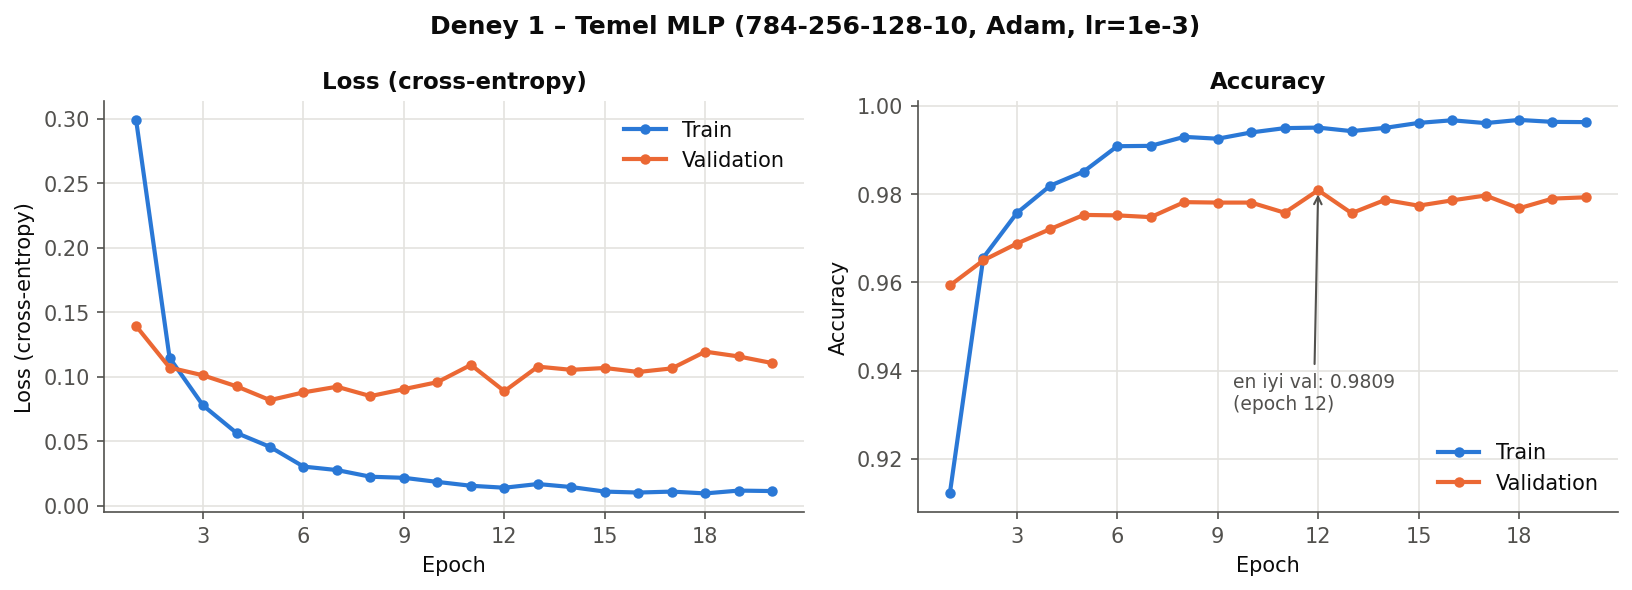

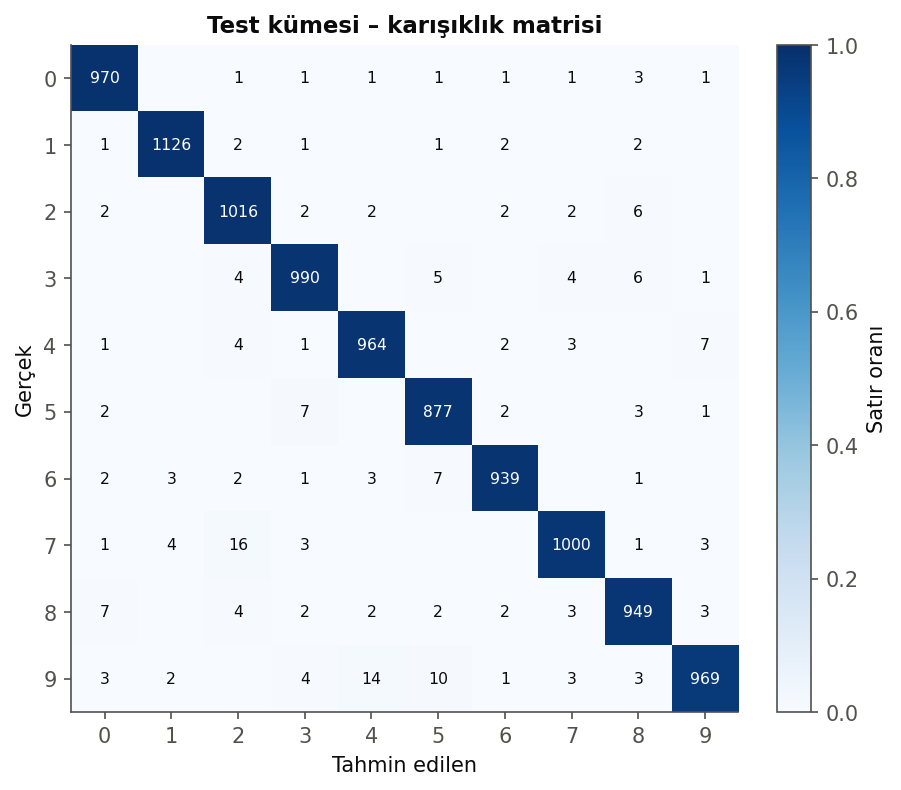

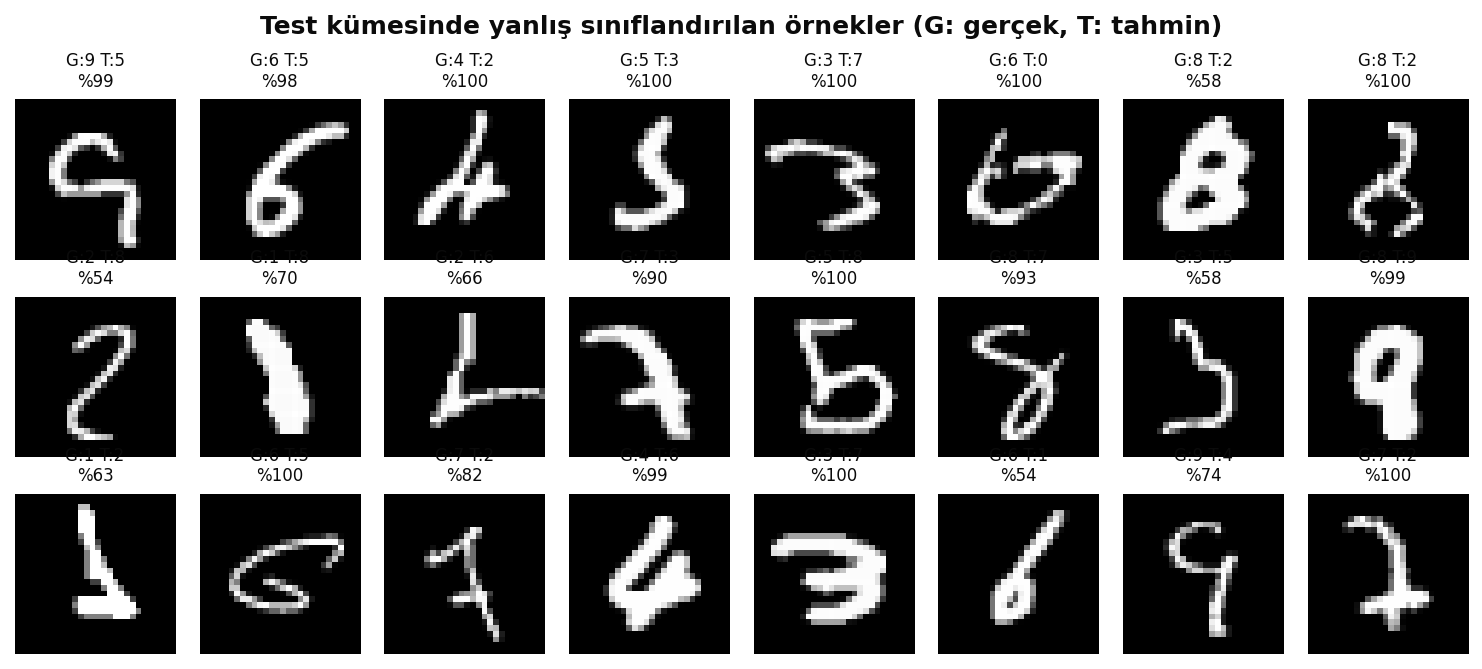

In [7]:
plot_curves(hist1, f"{OUT}/deney1_loss_accuracy.png", "Deney 1 – Temel MLP (784-256-128-10, Adam, lr=1e-3)")
goster(f"{OUT}/deney1_loss_accuracy.png")

probs = predict(model1, X_te, data["mean"], data["std"]).numpy()
y_pred, y_true = probs.argmax(1), y_te.numpy()
cm = np.zeros((10, 10), dtype=int); np.add.at(cm, (y_true, y_pred), 1)
plot_confusion(cm, f"{OUT}/deney1_confusion_matrix.png", "Test kümesi – karışıklık matrisi")
goster(f"{OUT}/deney1_confusion_matrix.png")
plot_misclassified(X_te.numpy(), y_true, y_pred, probs.max(1), f"{OUT}/deney1_yanlis_tahminler.png")
goster(f"{OUT}/deney1_yanlis_tahminler.png")

## 5. Deney 2 – Hiperparametre karşılaştırması



In [8]:
CONFIGS = [
    Config("temel", (256, 128)),
    Config("dar_128-64", (128, 64)),
    Config("genis_512-256", (512, 256)),
    Config("derin_512-256-128-64", (512, 256, 128, 64)),
    Config("sgd_lr0.01", optimizer="sgd", lr=0.01),
    Config("sgd_mom0.9_lr0.01", optimizer="sgd", lr=0.01, momentum=0.9),
    Config("adam_lr1e-4", lr=1e-4),
    Config("adam_lr1e-2", lr=1e-2),
    Config("batch_32", batch_size=32),
    Config("batch_512", batch_size=512),
    Config("dropout_0.3", dropout=0.3),
    Config("genis_dropout0.2_augment", (512, 256), dropout=0.2, augment=True),
]
GROUPS = {
    "Mimari (genişlik / derinlik)": ["temel", "dar_128-64", "genis_512-256", "derin_512-256-128-64"],
    "Optimizer": ["temel", "sgd_lr0.01", "sgd_mom0.9_lr0.01"],
    "Learning rate (Adam)": ["temel", "adam_lr1e-4", "adam_lr1e-2"],
    "Batch size": ["temel", "batch_32", "batch_512"],
    "Düzenlileştirme": ["temel", "dropout_0.3", "genis_dropout0.2_augment"],
}

histories, rows, models = {}, [], {}
for cfg in CONFIGS:
    m, h, s, _ = fit(cfg, data, verbose=False)
    histories[cfg.name], models[cfg.name] = h, m
    rows.append(s)
    print(f"{cfg.name:28s} en iyi val acc = {s['best_val_acc']:.4f}  ({s['train_time_s']:.0f} sn)")

best_name = max(rows, key=lambda r: r["best_val_acc"])["config"]["name"]
print("\nValidation'a göre en iyi yapılandırma:", best_name)

for r in rows:
    r["test_loss"], r["test_acc"] = evaluate(models[r["config"]["name"]], X_te, y_te, data["mean"], data["std"])

temel                        en iyi val acc = 0.9809  (46 sn)
dar_128-64                   en iyi val acc = 0.9778  (28 sn)
genis_512-256                en iyi val acc = 0.9822  (96 sn)
derin_512-256-128-64         en iyi val acc = 0.9807  (112 sn)
sgd_lr0.01                   en iyi val acc = 0.9593  (35 sn)
sgd_mom0.9_lr0.01            en iyi val acc = 0.9798  (37 sn)
adam_lr1e-4                  en iyi val acc = 0.9756  (43 sn)
adam_lr1e-2                  en iyi val acc = 0.9729  (64 sn)
batch_32                     en iyi val acc = 0.9797  (115 sn)
batch_512                    en iyi val acc = 0.9809  (34 sn)
dropout_0.3                  en iyi val acc = 0.9828  (63 sn)
genis_dropout0.2_augment     en iyi val acc = 0.9898  (134 sn)

Validation'a göre en iyi yapılandırma: genis_dropout0.2_augment


,yapılandırma,gizli,optimizer,lr,momentum,batch,dropout,augment,parametre,train loss,val loss,train acc,val acc (en iyi),test acc,süre (sn)
11,genis_dropout0.2_augment,512-256,adam,0.0010,0.0,128,0.2,True,535818,0.0855,0.0451,0.9739,0.9898,0.9879,134.1
10,dropout_0.3,256-128,adam,0.0010,0.0,128,0.3,False,235146,0.0386,0.0707,0.9873,0.9828,0.9810,63.5
2,genis_512-256,512-256,adam,0.0010,0.0,128,0.0,False,535818,0.0126,0.1027,0.9958,0.9822,0.9808,96.1
0,temel,256-128,adam,0.0010,0.0,128,0.0,False,235146,0.0114,0.1106,0.9963,0.9809,0.9800,46.4
9,batch_512,256-128,adam,0.0010,0.0,512,0.0,False,235146,0.0019,0.0874,0.9999,0.9809,0.9781,34.3
3,derin_512-256-128-64,512-256-128-64,adam,0.0010,0.0,128,0.0,False,575050,0.0089,0.1092,0.9969,0.9807,0.9792,112.3
5,sgd_mom0.9_lr0.01,256-128,sgd,0.0100,0.9,128,0.0,False,235146,0.0024,0.0769,1.0000,0.9798,0.9806,37.3
8,batch_32,256-128,adam,0.0010,0.0,32,0.0,False,235146,0.0127,0.2089,0.9962,0.9797,0.9778,115.0
1,dar_128-64,128-64,adam,0.0010,0.0,128,0.0,False,109386,0.0075,0.1154,0.9973,0.9778,0.9773,27.5
6,adam_lr1e-4,256-128,adam,0.0001,0.0,128,0.0,False,235146,0.0363,0.0799,0.9906,0.9756,0.9775,43.2


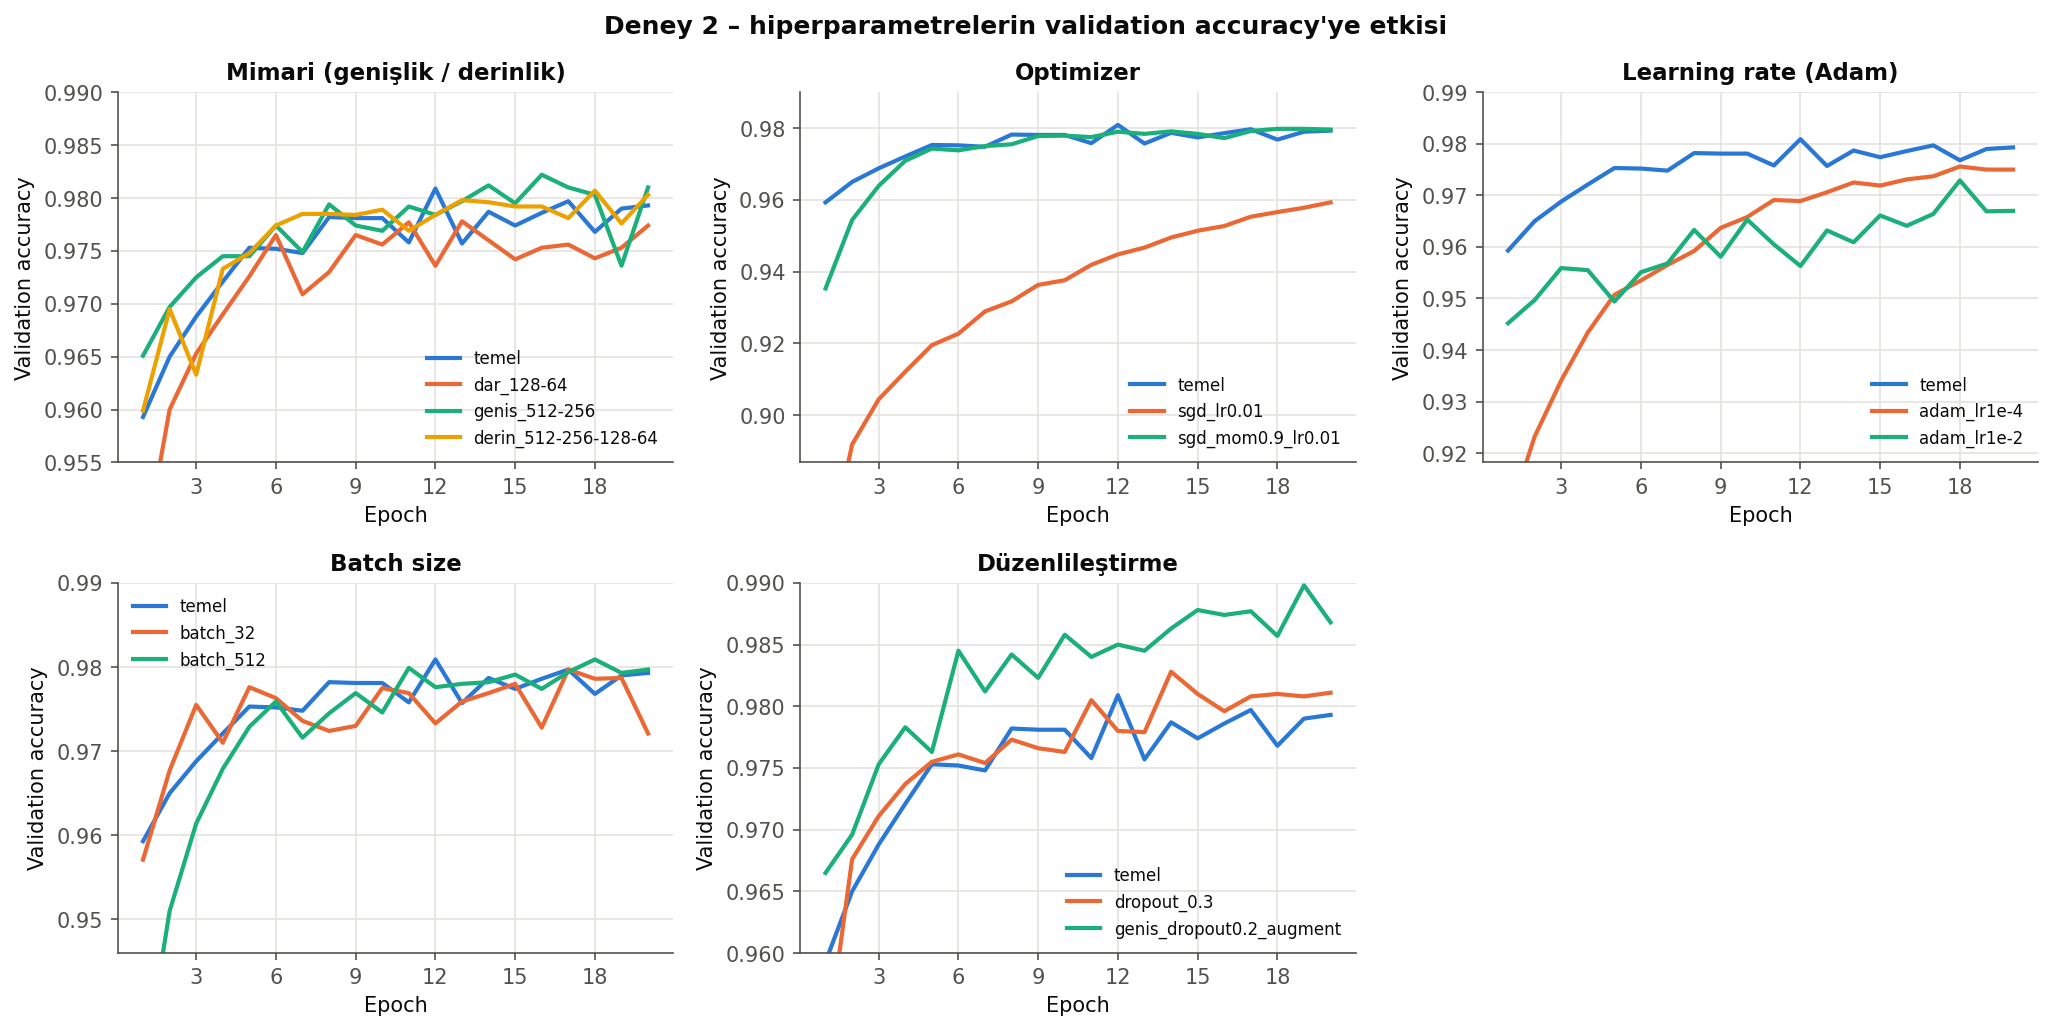

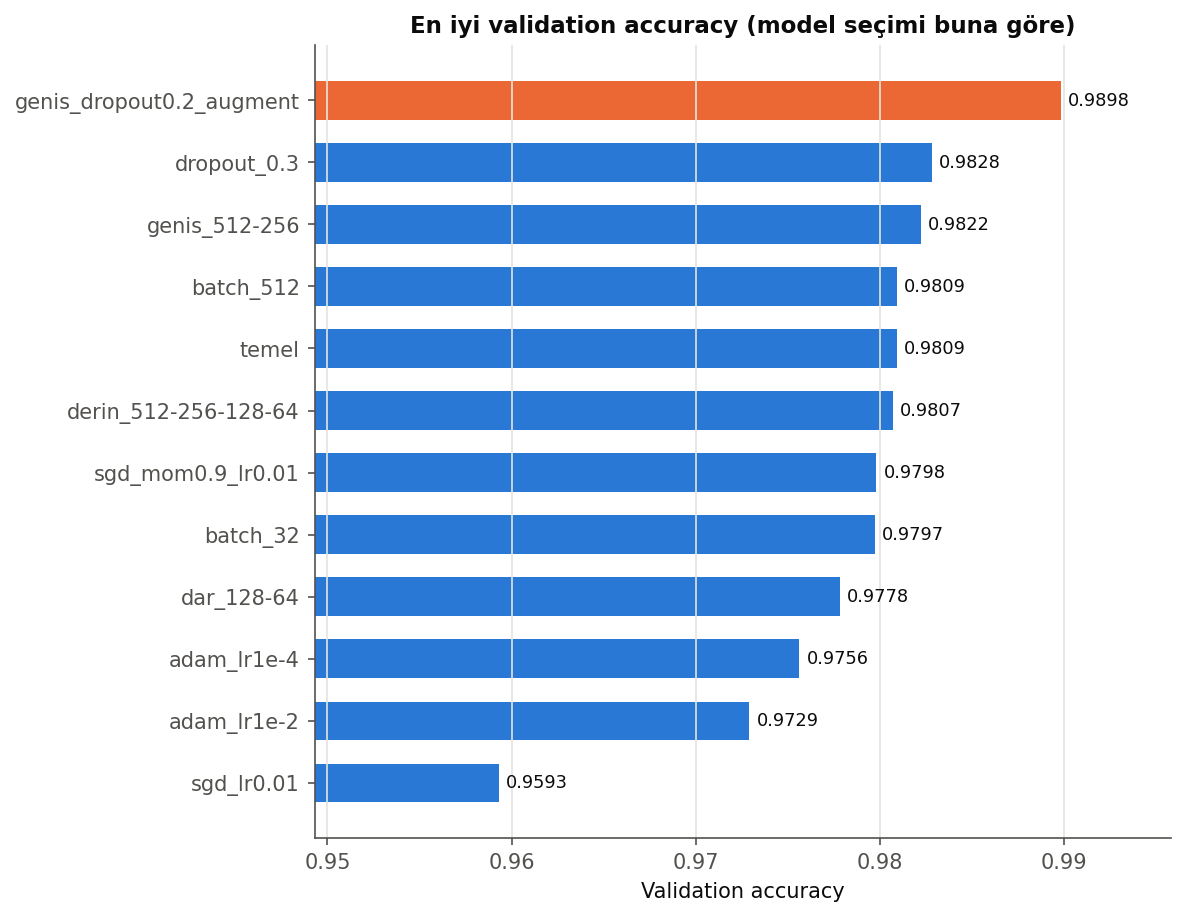

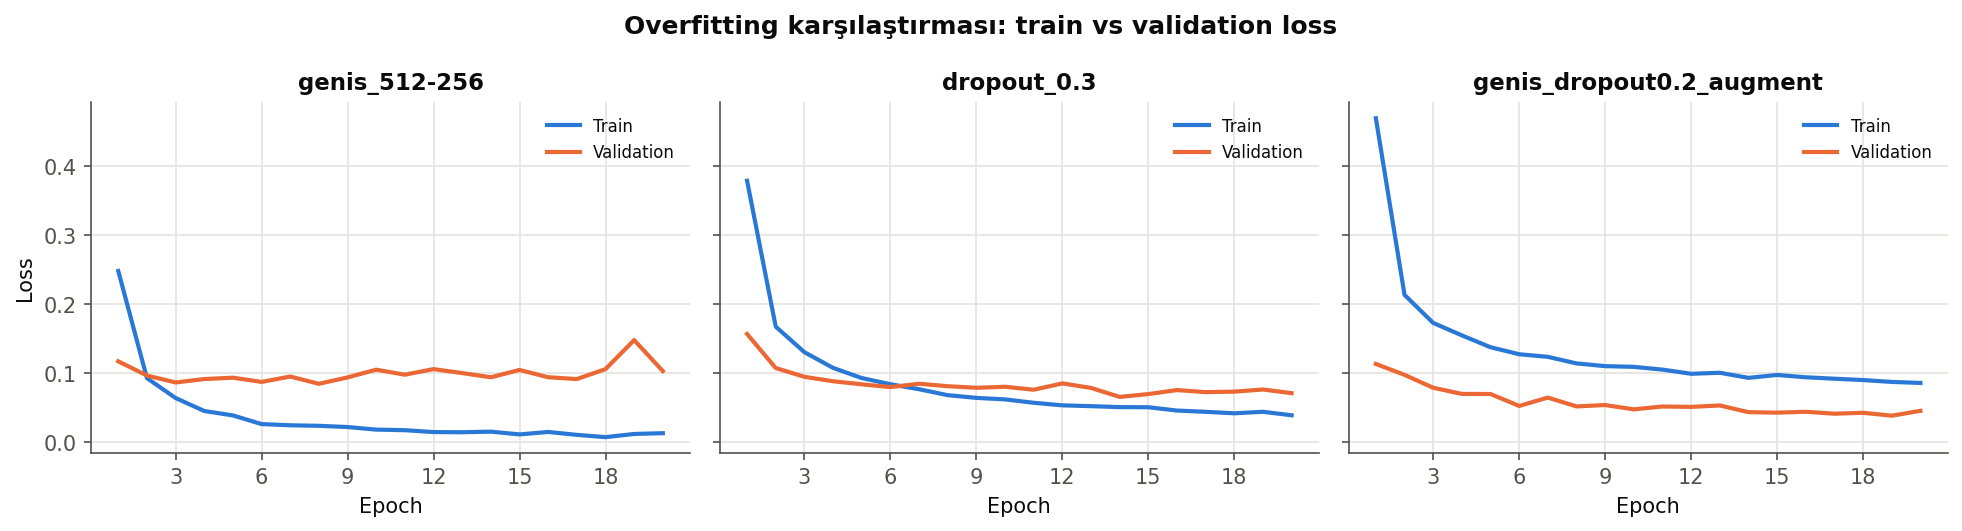

In [9]:
import pandas as pd
tablo = pd.DataFrame([{
    "yapılandırma": r["config"]["name"],
    "gizli": "-".join(map(str, r["config"]["hidden"])),
    "optimizer": r["config"]["optimizer"], "lr": r["config"]["lr"],
    "momentum": r["config"]["momentum"], "batch": r["config"]["batch_size"],
    "dropout": r["config"]["dropout"], "augment": r["config"]["augment"],
    "parametre": r["params"],
    "train loss": round(r["final_train_loss"], 4), "val loss": round(r["final_val_loss"], 4),
    "train acc": round(r["final_train_acc"], 4), "val acc (en iyi)": round(r["best_val_acc"], 4),
    "test acc": round(r["test_acc"], 4), "süre (sn)": round(r["train_time_s"], 1),
} for r in rows])
tablo.to_csv(f"{OUT}/deney2_karsilastirma.csv", index=False)
display(tablo.sort_values("val acc (en iyi)", ascending=False))

plot_val_curves_groups(GROUPS, histories, f"{OUT}/deney2_val_accuracy_gruplar.png")
goster(f"{OUT}/deney2_val_accuracy_gruplar.png")
plot_bar(list(tablo["yapılandırma"]), list(tablo["val acc (en iyi)"]), f"{OUT}/deney2_en_iyi_val.png",
         "En iyi validation accuracy (model seçimi buna göre)", "Validation accuracy", highlight=best_name)
goster(f"{OUT}/deney2_en_iyi_val.png")
plot_overfit(histories, ["genis_512-256", "dropout_0.3", "genis_dropout0.2_augment"], f"{OUT}/deney2_overfitting.png")
goster(f"{OUT}/deney2_overfitting.png")

## 6. Kendi el yazımla öğrenci numaram



In [10]:
"""Bu modül adım adım şu dönüşümleri yapar:
  1. Gri tonlamaya çevirme (+ EXIF yönünü düzeltme)
  2. Aydınlatma düzeltme: kâğıdın arka plan parlaklığı tahmin edilip bölünür
  3. Renk ters çevirme: mürekkep = 1 (beyaz), kâğıt = 0 (siyah)  -> MNIST ile uyumlu
  4. Otsu eşikleme ile mürekkep maskesi + küçük gürültü lekelerinin silinmesi
  5. Bağlı bileşen analizi ile rakamların ayrıştırılması (öğrenci numarası için)
  6. Her rakam için: çizgi kalınlığını MNIST'e benzetme, 20x20'ye sığdırma,
     28x28'e yerleştirme, kütle merkezini ortalama
  7. Normalizasyon: [0,1] ölçekleme + eğitimdeki (x - mean) / std
"""
import numpy as np
from PIL import Image, ImageOps
from scipy import ndimage

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".webp", ".tif", ".tiff")


# --------------------------------------------------------------------------- 1
def load_gray(path, max_side=1200):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img)
    if img.mode in ("RGBA", "LA") or "transparency" in img.info:
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img.convert("RGBA"))
    img = img.convert("L")
    s = max_side / max(img.size)
    if s < 1:
        img = img.resize((round(img.width * s), round(img.height * s)), Image.LANCZOS)
    return np.asarray(img, dtype=np.float32) / 255.0


# --------------------------------------------------------------------------- 2-3
def ink_map(gray):
    h, w = gray.shape
    if np.median(gray) < 0.5:
        gray = 1.0 - gray
    k = int(np.clip(max(h, w) // 6, 15, min(h, w)))
    bg = ndimage.grey_closing(gray, size=(k, k))
    bg = ndimage.gaussian_filter(bg, sigma=k / 4)
    bg = np.maximum(bg, 1e-3)
    ink = np.clip(1.0 - gray / bg, 0.0, 1.0)
    return ink


# --------------------------------------------------------------------------- 4
def otsu(values, bins=256):
    hist, edges = np.histogram(values, bins=bins, range=(0, 1))
    p = hist.astype(np.float64) / max(hist.sum(), 1)
    w0 = np.cumsum(p)
    m = np.cumsum(p * (edges[:-1] + edges[1:]) / 2)
    mt = m[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        var = (mt * w0 - m) ** 2 / (w0 * (1 - w0))
    var = np.nan_to_num(var)
    return float(edges[np.argmax(var) + 1])


def ink_mask(ink):
    t = max(otsu(ink), 0.12)
    mask = ink > t
    mask = ndimage.binary_opening(mask, iterations=1)
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask, t
    areas = ndimage.sum(mask, lab, index=np.arange(1, n + 1))
    keep = np.zeros(n + 1, bool)
    keep[1:] = areas >= 15
    sls = ndimage.find_objects(lab)
    extent = np.array([max(s[0].stop - s[0].start, s[1].stop - s[1].start) for s in sls])
    ref = np.median(extent[keep[1:]]) if keep[1:].any() else np.median(extent)
    for i, (ys, xs) in enumerate(sls, start=1):
        touches = ys.start == 0 or xs.start == 0 or ys.stop == mask.shape[0] or xs.stop == mask.shape[1]
        if touches and extent[i - 1] > 2.5 * ref:
            keep[i] = False
    cand = np.sort(areas[keep[1:]])[::-1]
    if len(cand):
        typical = np.median(cand[:12])
        keep[1:] &= areas >= max(15, 0.08 * typical)
    return keep[lab], t


# --------------------------------------------------------------------------- 5
def _boxes_from_labels(lab, n):
    out = []
    for i, sl in enumerate(ndimage.find_objects(lab), start=1):
        if sl is None:
            continue
        ys, xs = sl
        out.append({"ids": [i], "y0": ys.start, "y1": ys.stop, "x0": xs.start, "x1": xs.stop})
    return out


def _merge(a, b):
    return {"ids": a["ids"] + b["ids"], "y0": min(a["y0"], b["y0"]), "y1": max(a["y1"], b["y1"]),
            "x0": min(a["x0"], b["x0"]), "x1": max(a["x1"], b["x1"])}


def segment_digits(mask, n_expected=None):
    if not mask.any():
        return [], np.zeros_like(mask, int)
    dt = ndimage.distance_transform_edt(mask)
    sw = max(1.0, 2 * np.percentile(dt[mask], 90))
    grown = ndimage.binary_dilation(mask, iterations=max(1, int(round(sw * 0.5))))
    lab, n = ndimage.label(grown)
    lab = lab * mask
    boxes = sorted(_boxes_from_labels(lab, n), key=lambda b: b["x0"])

    changed = True
    while changed:
        changed = False
        for i in range(len(boxes)):
            for j in range(i + 1, len(boxes)):
                a, b = boxes[i], boxes[j]
                ov = min(a["x1"], b["x1"]) - max(a["x0"], b["x0"])
                if ov > 0.5 * min(a["x1"] - a["x0"], b["x1"] - b["x0"]):
                    boxes[i] = _merge(a, b)
                    boxes.pop(j)
                    changed = True
                    break
            if changed:
                break
    boxes.sort(key=lambda b: b["x0"])

    if boxes:
        hmed = np.median([b["y1"] - b["y0"] for b in boxes])
        boxes = [b for b in boxes if (b["y1"] - b["y0"]) >= 0.3 * hmed]

    if n_expected:
        while len(boxes) > n_expected:
            gaps = [boxes[i + 1]["x0"] - boxes[i]["x1"] for i in range(len(boxes) - 1)]
            i = int(np.argmin(gaps))
            boxes[i] = _merge(boxes[i], boxes.pop(i + 1))
        while len(boxes) < n_expected:
            i = int(np.argmax([b["x1"] - b["x0"] for b in boxes]))
            b = boxes[i]
            region = np.isin(lab[b["y0"]:b["y1"], b["x0"]:b["x1"]], b["ids"])
            w = region.shape[1]
            proj = region.sum(0).astype(float)
            lo, hi = int(w * 0.25), max(int(w * 0.75), int(w * 0.25) + 1)
            cut = lo + int(np.argmin(proj[lo:hi]))
            new_id = lab.max() + 1
            sub = lab[b["y0"]:b["y1"], b["x0"]:b["x1"]]
            right = np.zeros_like(region)
            right[:, cut:] = region[:, cut:]
            sub[right] = new_id
            left_box = {"ids": b["ids"], "y0": b["y0"], "y1": b["y1"], "x0": b["x0"], "x1": b["x0"] + cut}
            right_box = {"ids": [new_id], "y0": b["y0"], "y1": b["y1"], "x0": b["x0"] + cut, "x1": b["x1"]}
            boxes[i:i + 1] = [left_box, right_box]
    return boxes, lab


# --------------------------------------------------------------------------- 6
def _disk(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x * x + y * y <= r * r


def to_mnist_28(digit_ink, box_size=20, target_stroke=0.13):
    soft = digit_ink.astype(np.float32)
    m = soft > 0.5
    if not m.any():
        return np.zeros((28, 28), np.float32)

    ys, xs = np.nonzero(m)
    L = max(np.ptp(ys) + 1, np.ptp(xs) + 1)
    sw = 2 * np.percentile(ndimage.distance_transform_edt(m)[m], 90)
    target = target_stroke * L
    pad = int(target) + 2
    soft = np.pad(soft, pad)
    if sw < 0.8 * target:
        r = int(round((target - sw) / 2))
        if r > 0:
            soft = ndimage.grey_dilation(soft, footprint=_disk(r))
    elif sw > 1.6 * target:
        r = int(round((sw - target) / 2))
        if r > 0:
            thinner = ndimage.grey_erosion(soft, footprint=_disk(r))
            if (thinner > 0.5).sum() > 0.2 * m.sum():
                soft = thinner

    ys, xs = np.nonzero(soft > 0.05)
    if len(ys) == 0:
        return np.zeros((28, 28), np.float32)
    soft = soft[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = soft.shape

    s = box_size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = np.asarray(Image.fromarray(soft, mode="F").resize((nw, nh), Image.LANCZOS))
    small = np.clip(small, 0, 1)

    out = np.zeros((28, 28), np.float32)
    y0, x0 = (28 - nh) // 2, (28 - nw) // 2
    out[y0:y0 + nh, x0:x0 + nw] = small
    cy, cx = ndimage.center_of_mass(out)
    dy, dx = int(round(13.5 - cy)), int(round(13.5 - cx))
    ys, xs = np.nonzero(out > 0)
    dy = int(np.clip(dy, -ys.min(), 27 - ys.max()))
    dx = int(np.clip(dx, -xs.min(), 27 - xs.max()))
    out = np.roll(out, (dy, dx), axis=(0, 1))
    if out.max() > 0:
        out = out / out.max()
    return out.astype(np.float32)


# --------------------------------------------------------------------------- hepsi
def process_image(path, n_expected=None, single=False):

    gray = load_gray(path)
    ink = ink_map(gray)
    mask, t = ink_mask(ink)

    if mask.any():
        hi = np.percentile(ink[mask], 90)
        lo = 0.5 * t
        soft = np.clip((ink - lo) / max(hi - lo, 1e-3), 0, 1)
    else:
        soft = np.zeros_like(ink)

    if single:
        boxes, lab = [], mask.astype(int)
        if mask.any():
            ys, xs = np.nonzero(mask)
            boxes = [{"ids": [1], "y0": ys.min(), "y1": ys.max() + 1,
                      "x0": xs.min(), "x1": xs.max() + 1}]
    else:
        boxes, lab = segment_digits(mask, n_expected)

    digits = []
    for b in boxes:
        sl = (slice(b["y0"], b["y1"]), slice(b["x0"], b["x1"]))
        region = np.isin(lab[sl], b["ids"])
        region = ndimage.binary_dilation(region, iterations=2)
        digits.append(to_mnist_28(soft[sl] * region))

    return {"gray": gray, "ink": soft, "mask": mask, "boxes": boxes,
            "digits": np.stack(digits) if digits else np.zeros((0, 28, 28), np.float32)}

In [11]:
def figure_number(path, res, probs, truth, save):
    n = len(res["digits"])
    names = list(probs)
    fig = plt.figure(figsize=(max(8, 1.25 * n + 1), 3.2 + 1.35 * (1 + len(names))))
    gs = fig.add_gridspec(2 + len(names), max(n, 1),
                          height_ratios=[2.6, 1.2] + [0.55] * len(names))
    ax = fig.add_subplot(gs[0, :])
    ax.imshow(res["gray"], cmap="gray")
    for k, b in enumerate(res["boxes"]):
        ax.add_patch(patches.Rectangle((b["x0"], b["y0"]), b["x1"] - b["x0"], b["y1"] - b["y0"],
                                       fill=False, ec=SERIES[1], lw=1.5))
        ax.text(b["x0"], b["y0"] - 4, str(k + 1), color=SERIES[1], fontsize=9, va="bottom")
    ax.set_title(f"{os.path.basename(path)} – bulunan rakam bölgeleri", fontsize=10)
    ax.axis("off")
    for k in range(n):
        a = fig.add_subplot(gs[1, k])
        a.imshow(res["digits"][k], cmap="gray", vmin=0, vmax=1)
        t = f"gerçek {truth[k]}" if truth and k < len(truth) else f"#{k + 1}"
        a.set_title(t, fontsize=8)
        a.axis("off")
        for r, name in enumerate(names):
            a2 = fig.add_subplot(gs[2 + r, k])
            a2.axis("off")
            p = probs[name][k]
            pred = int(p.argmax())
            ok = truth and k < len(truth) and str(pred) == truth[k]
            col = "#008300" if ok else ("#e34948" if truth else "#0b0b0b")
            mark = ("✓ " if ok else "✗ ") if truth else ""
            a2.text(0.5, 0.5, f"{mark}{pred}  %{p.max() * 100:.0f}", ha="center", va="center",
                    fontsize=9, color=col, transform=a2.transAxes)
            if k == 0:
                a2.text(-0.15, 0.5, name, ha="right", va="center", fontsize=8, color=INK2,
                        transform=a2.transAxes)
    fig.suptitle("Kendi el yazım → MNIST formatı (28x28) → MLP tahmini", fontweight="bold")
    fig.savefig(save, bbox_inches="tight", dpi=150)
    plt.close(fig)


def figure_steps(path, res, save):
    h, w = res["gray"].shape
    fig, axes = plt.subplots(1, 3, figsize=(12, 4 * h / w + 0.9))
    for a, img, t in zip(axes, [res["gray"], res["ink"], res["mask"]],
                         ["1) gri tonlama", "2-3) aydınlatma düzeltme + ters çevirme",
                          "4) eşikleme (mürekkep maskesi)"]):
        a.imshow(img, cmap="gray")
        a.set_title(t, fontsize=10)
        a.axis("off")
    fig.suptitle(os.path.basename(path), fontsize=10)
    fig.tight_layout()
    fig.savefig(save, dpi=130)
    plt.close(fig)


def figure_shift(own, labels, save, n_ref=4):

    data = load_mnist()
    X, y = data["train"]
    rng = np.random.default_rng(0)
    rows = len(own)
    fig, axes = plt.subplots(rows, 1 + n_ref, figsize=(1.3 * (1 + n_ref), 1.35 * rows),
                             squeeze=False)
    for i in range(rows):
        axes[i, 0].imshow(own[i], cmap="gray", vmin=0, vmax=1)
        axes[i, 0].set_ylabel(f"{labels[i]}", rotation=0, labelpad=12)
        idx = rng.choice(np.where(y.numpy() == int(labels[i]))[0], n_ref, replace=False)
        for j, k in enumerate(idx):
            axes[i, j + 1].imshow(X[k], cmap="gray")
    for a in axes.ravel():
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    axes[0, 0].set_title("benim", fontsize=9)
    for j in range(n_ref):
        axes[0, j + 1].set_title("MNIST", fontsize=9)
    fig.suptitle("Dağılım farkı (distribution shift)", fontweight="bold", fontsize=10)
    fig.tight_layout()
    fig.savefig(save, dpi=130)
    plt.close(fig)

    Xn = X.numpy()
    stats = {
        "mnist_ortalama_parlaklik": float(Xn.mean()),
        "benim_ortalama_parlaklik": float(np.mean(own)),
        "mnist_murekkep_orani": float((Xn > 0.5).mean()),
        "benim_murekkep_orani": float((np.asarray(own) > 0.5).mean()),
    }
    return stats


In [12]:

try:
    from google.colab import files
    yuklenen = files.upload()
    paths = list(yuklenen.keys())
except ImportError:
    paths = sorted(p for p in glob.glob("el_yazisi/*") if p.lower().endswith(IMG_EXT))
print("Görüntüler:", paths)
os.makedirs("el_yazisi", exist_ok=True)
for p in paths:
    if not p.startswith("el_yazisi/"):
        os.replace(p, f"el_yazisi/{os.path.basename(p)}")
paths = [f"el_yazisi/{os.path.basename(p)}" for p in paths]

Saving numara_1_kalin_kalem.jpg to numara_1_kalin_kalem.jpg
Saving numara_2_ince_hizli.jpg to numara_2_ince_hizli.jpg
Saving numara_3_ince_duzgun.jpg to numara_3_ince_duzgun.jpg
Görüntüler: ['numara_1_kalin_kalem.jpg', 'numara_2_ince_hizli.jpg', 'numara_3_ince_duzgun.jpg']


/tmp/ipykernel_52045/2384647582.py:189: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  small = np.asarray(Image.fromarray(soft, mode="F").resize((nw, nh), Image.LANCZOS))



el_yazisi/numara_1_kalin_kalem.jpg: 11 rakam bulundu
  temel (Deney 1)                          -> 23120205072
  genis_dropout0.2_augment (Deney 2 en iyi) -> 23120205072


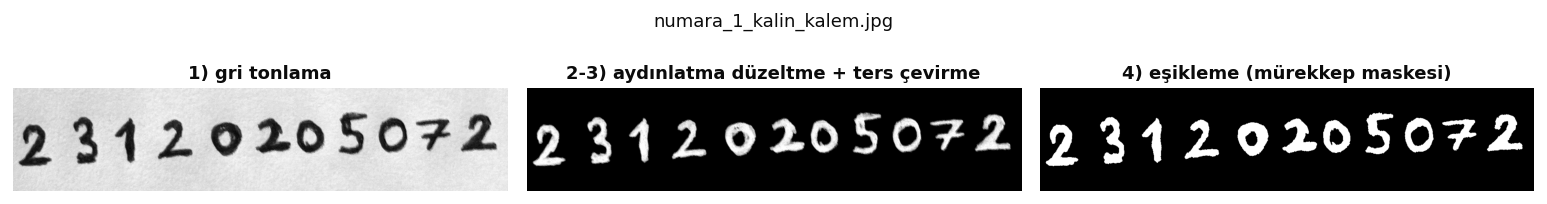

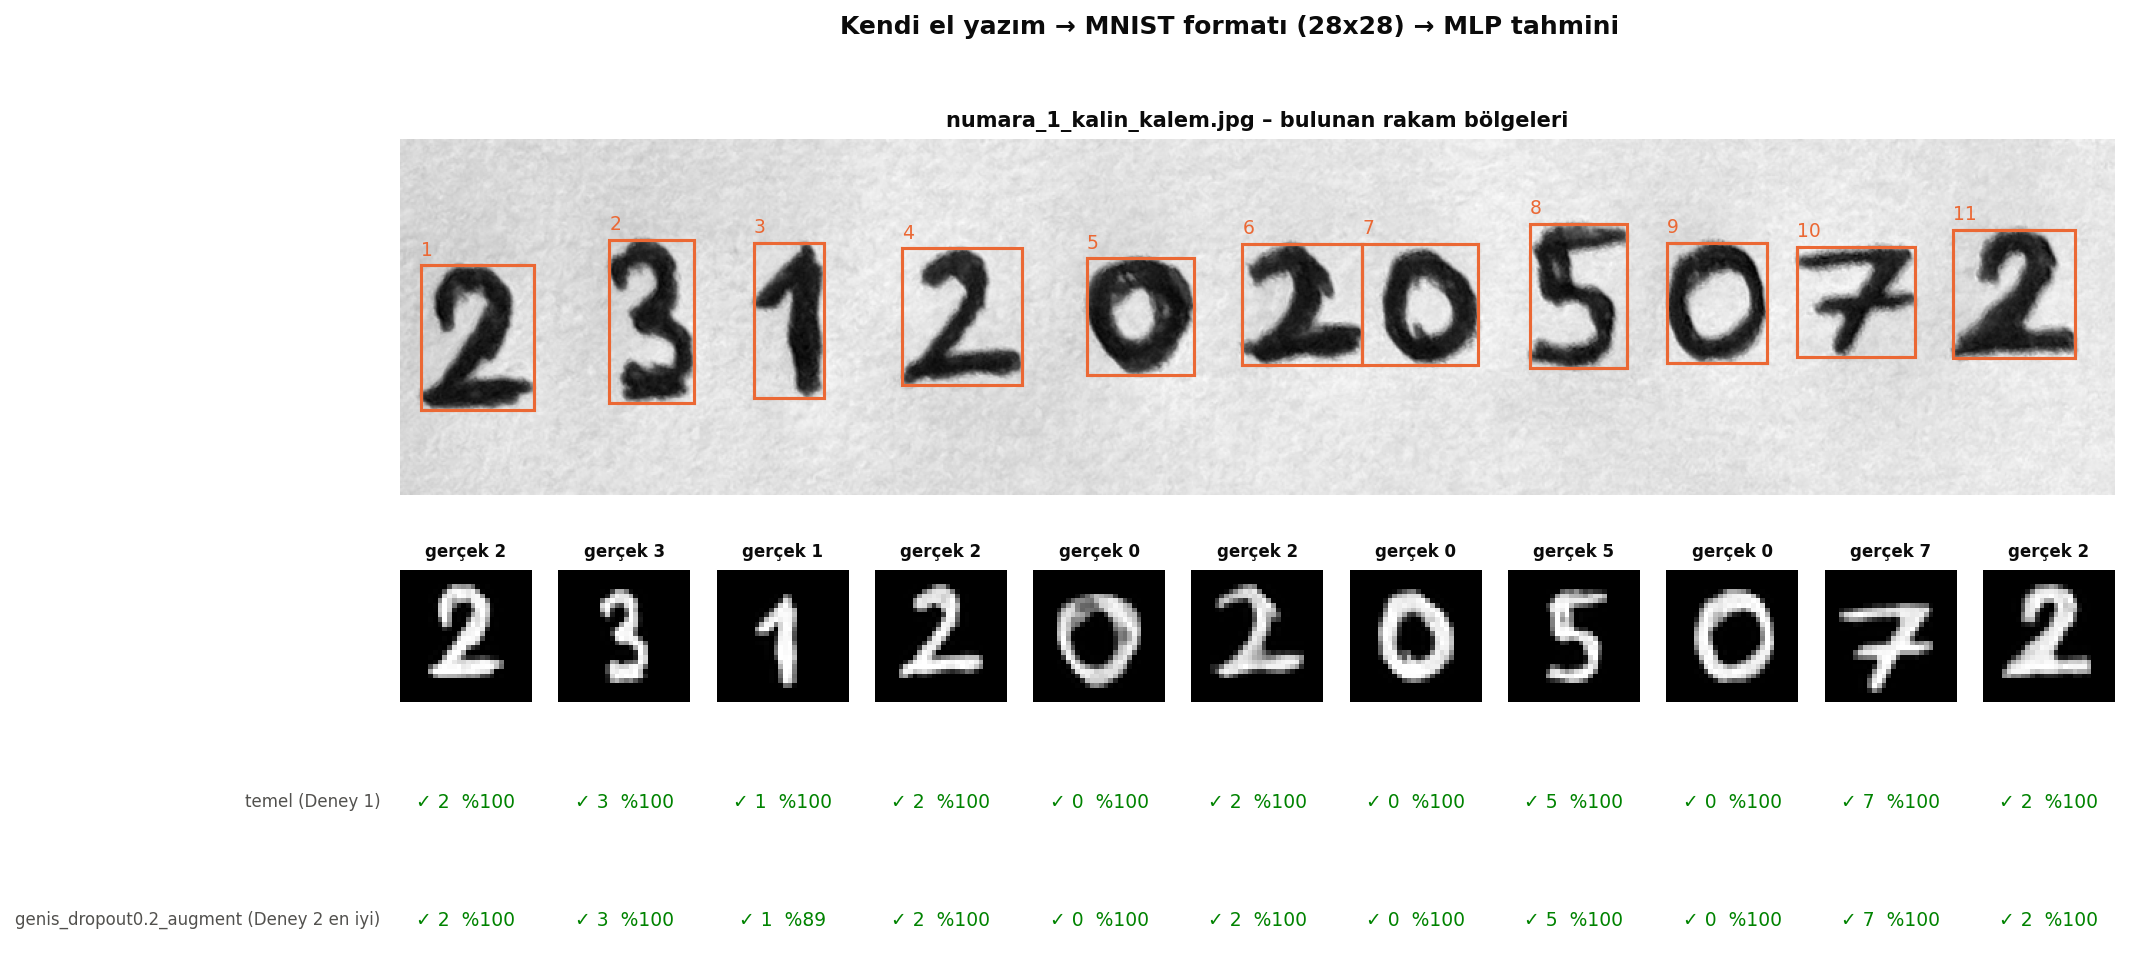


el_yazisi/numara_2_ince_hizli.jpg: 11 rakam bulundu
  temel (Deney 1)                          -> 23120295072
  genis_dropout0.2_augment (Deney 2 en iyi) -> 23120205072


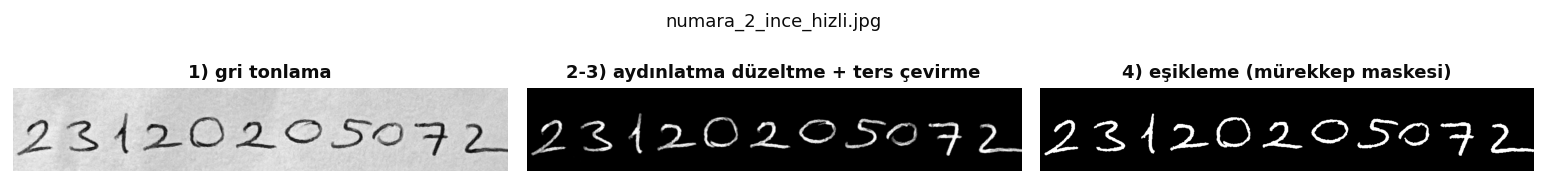

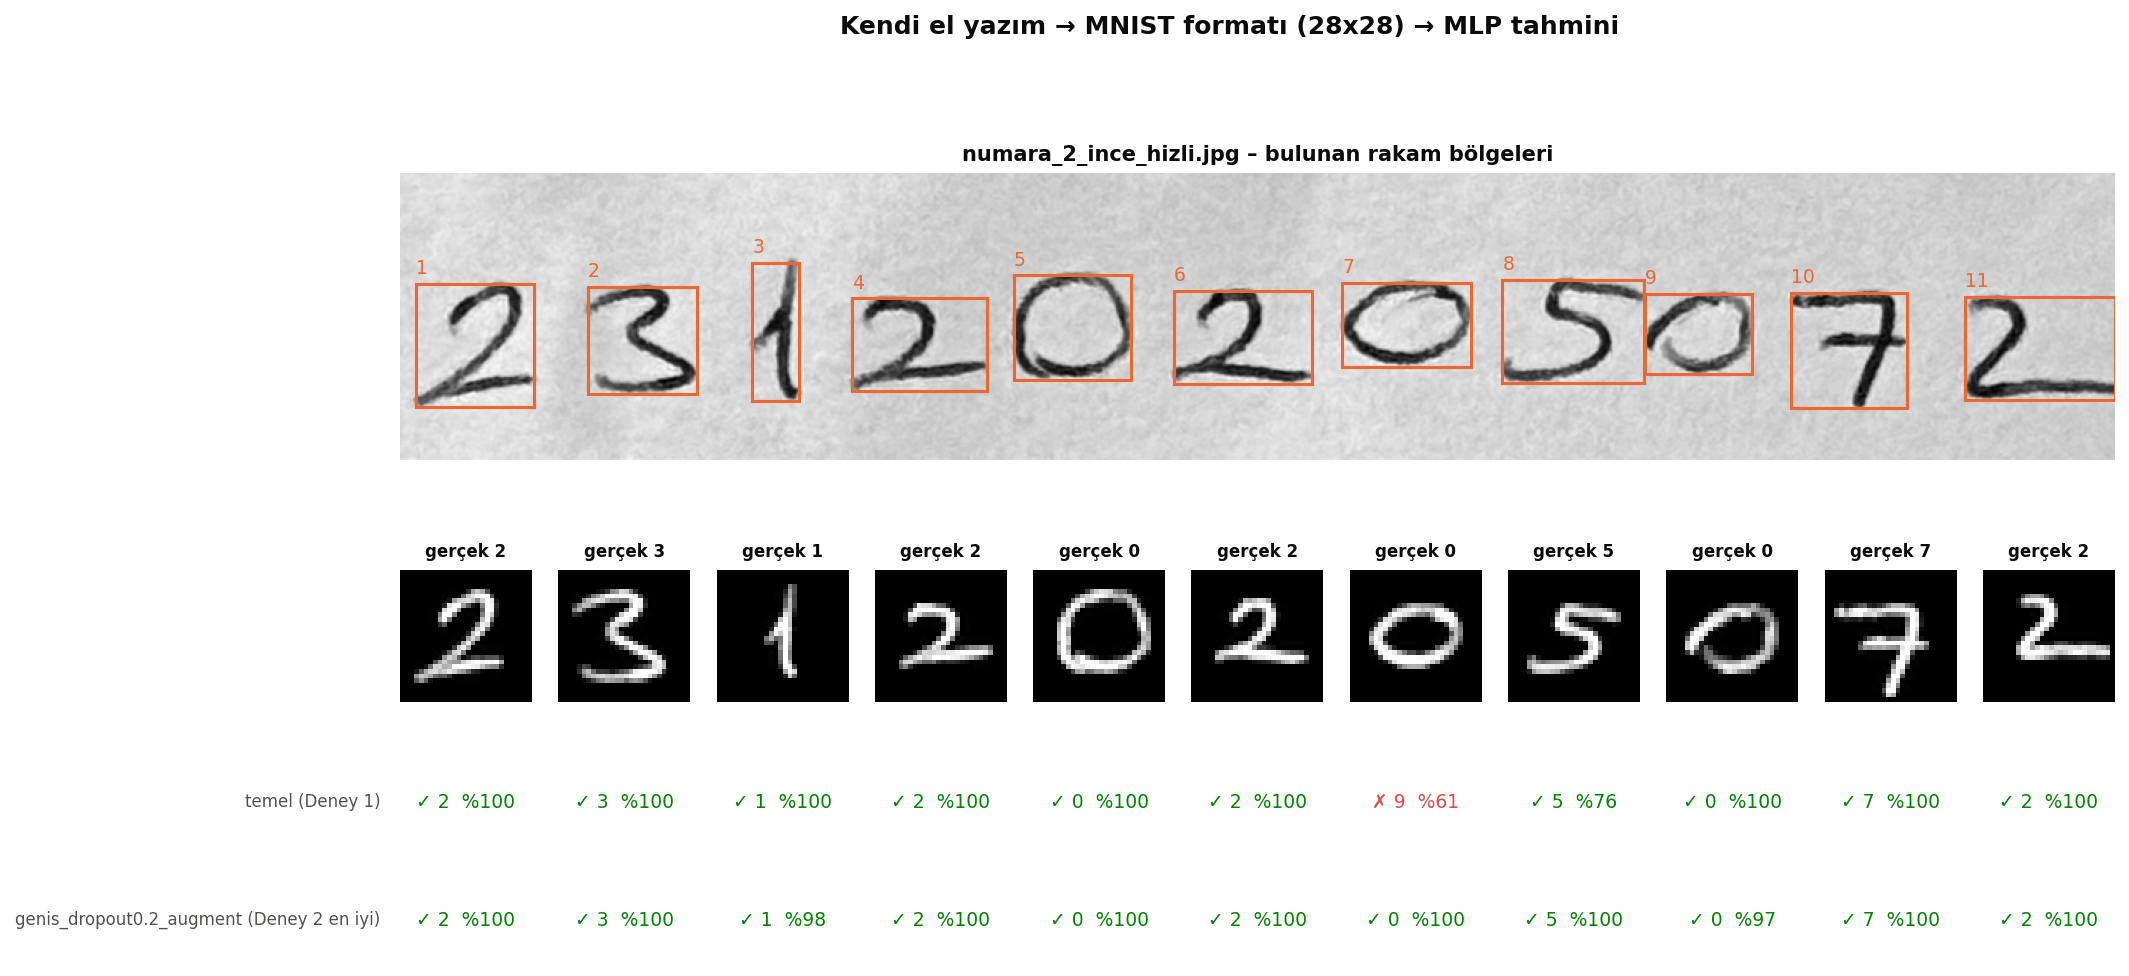


el_yazisi/numara_3_ince_duzgun.jpg: 11 rakam bulundu
  temel (Deney 1)                          -> 23120205072
  genis_dropout0.2_augment (Deney 2 en iyi) -> 23120205072


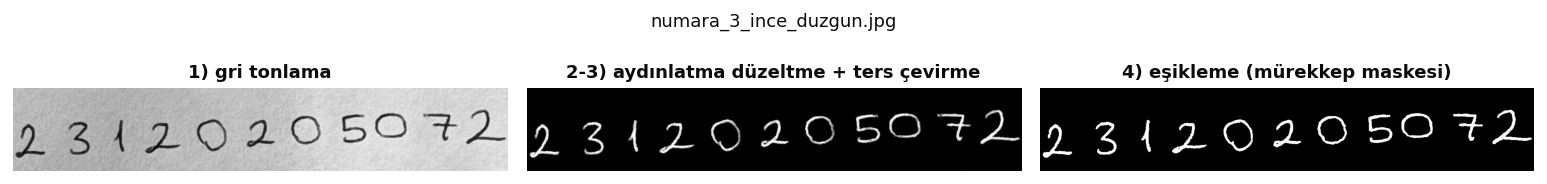

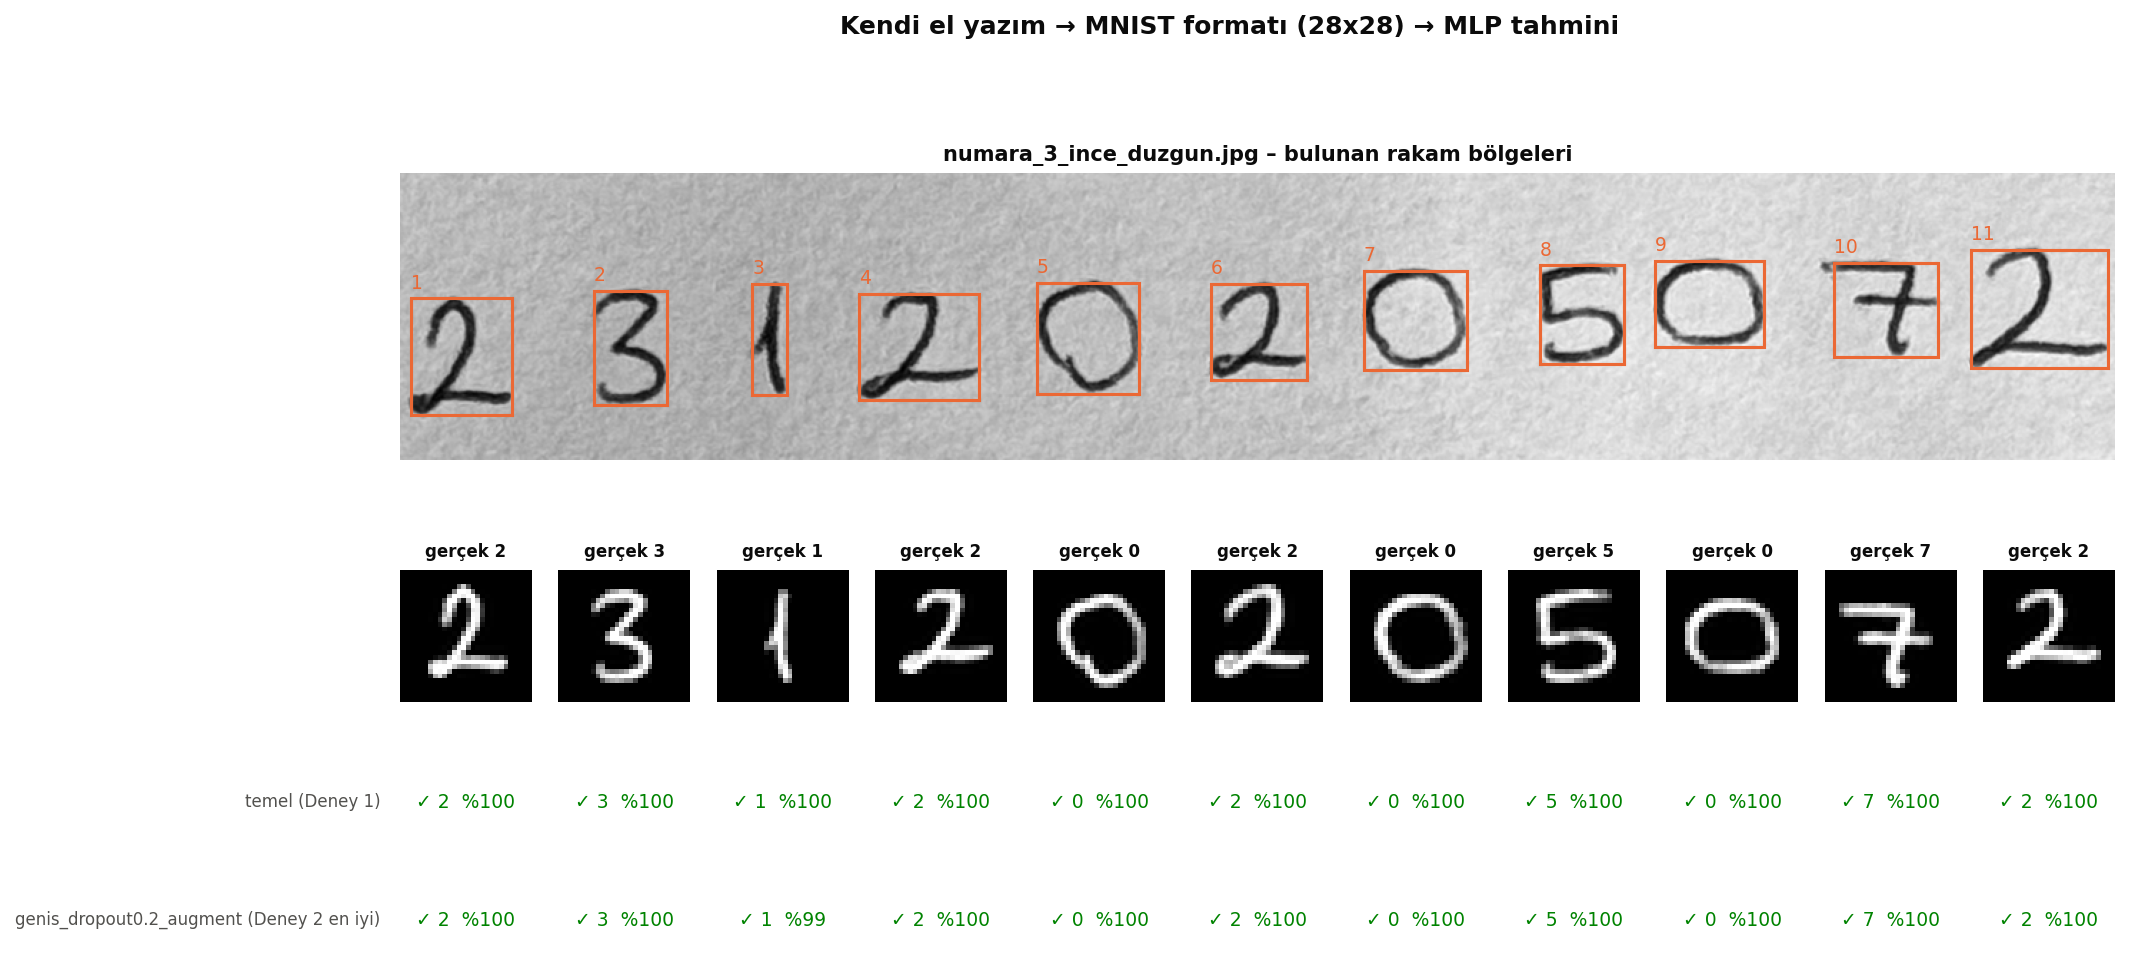


===== KENDİ EL YAZIM: RAKAM DOĞRULUĞU =====
temel (Deney 1)                          32/33 = %97.0
genis_dropout0.2_augment (Deney 2 en iyi) 33/33 = %100.0


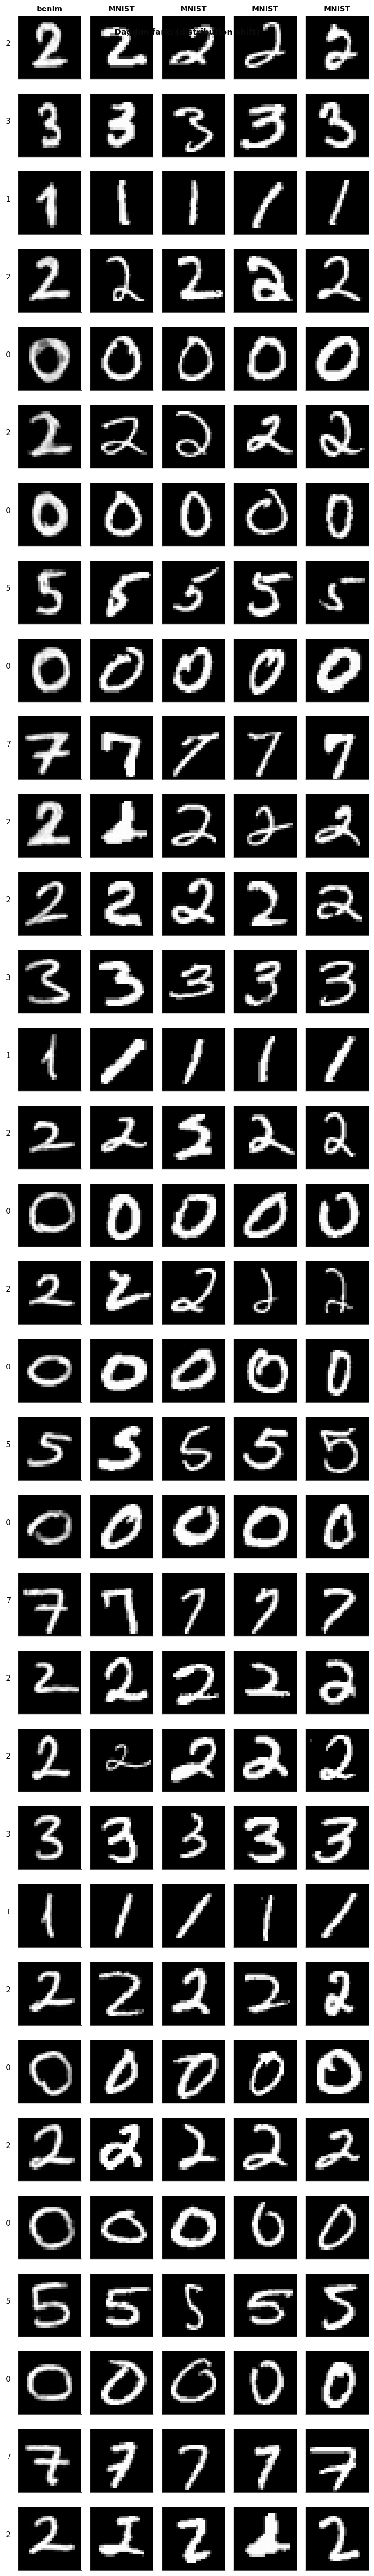

{
  "mnist_ortalama_parlaklik": 0.13059952855110168,
  "benim_ortalama_parlaklik": 0.13206656277179718,
  "mnist_murekkep_orani": 0.13219298469387755,
  "benim_murekkep_orani": 0.1380643166357452
}


In [13]:
tahmin_modelleri = {"temel (Deney 1)": model1, f"{best_name} (Deney 2 en iyi)": models[best_name]}
truth = list(OGRENCI_NO) if OGRENCI_NO else None
os.makedirs(f"{OUT}/islenmis_28x28", exist_ok=True)
dogru = {n: 0 for n in tahmin_modelleri}; toplam = 0; tum_rakamlar = []

for path in paths:
    stem = os.path.splitext(os.path.basename(path))[0]
    res = process_image(path, n_expected=len(truth) if truth else None)
    x = torch.from_numpy(res["digits"])
    probs = {n: torch.softmax(m.eval()(normalize(x, data["mean"], data["std"])), 1).detach().numpy()
             for n, m in tahmin_modelleri.items()}
    for k, d in enumerate(res["digits"]):
        Image.fromarray((d * 255).astype(np.uint8)).save(f"{OUT}/islenmis_28x28/{stem}_{k + 1}.png")

    print(f"\n{path}: {len(res['digits'])} rakam bulundu")
    for n, p in probs.items():
        tahmin = "".join(str(int(v.argmax())) for v in p)
        print(f"  {n:40s} -> {tahmin}")
        if truth:
            dogru[n] += sum(a == b for a, b in zip(tahmin, truth))
    if truth:
        toplam += min(len(truth), len(res["digits"]))
        tum_rakamlar += list(res["digits"][:len(truth)])

    figure_steps(path, res, f"{OUT}/{stem}_on_isleme.png"); goster(f"{OUT}/{stem}_on_isleme.png")
    figure_number(path, res, probs, truth, f"{OUT}/{stem}_tahmin.png"); goster(f"{OUT}/{stem}_tahmin.png")

if truth and toplam:
    print("\n===== KENDİ EL YAZIM: RAKAM DOĞRULUĞU =====")
    for n in tahmin_modelleri:
        print(f"{n:40s} {dogru[n]}/{toplam} = %{100 * dogru[n] / toplam:.1f}")
    etiketler = (truth * len(paths))[:len(tum_rakamlar)]
    stats = figure_shift(np.stack(tum_rakamlar), etiketler, f"{OUT}/dagilim_farki.png")
    goster(f"{OUT}/dagilim_farki.png")
    print(json.dumps(stats, indent=2, ensure_ascii=False))

/tmp/ipykernel_52045/2384647582.py:189: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  small = np.asarray(Image.fromarray(soft, mode="F").resize((nw, nh), Image.LANCZOS))
/tmp/ipykernel_52045/2764371006.py:12: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  small = np.clip(np.asarray(Image.fromarray(c, "F").resize((nw, nh), Image.LANCZOS)), 0, 1)
/tmp/ipykernel_52045/2764371006.py:23: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return np.clip(np.asarray(Image.fromarray(c, "F").resize((28, 28), Image.LANCZOS)), 0, 1)


,Ön işleme,Temel (Deney 1),En iyi (Deney 2)
0,Tam ön işleme,32/33 (%97),33/33 (%100)
1,Çizgi kalınlığı ayarı yok,31/33 (%94),33/33 (%100)
2,20x20 kutu + ortalama yok,10/33 (%30),20/33 (%61)
3,Renk ters çevrilmemiş,0/33 (%0),0/33 (%0)


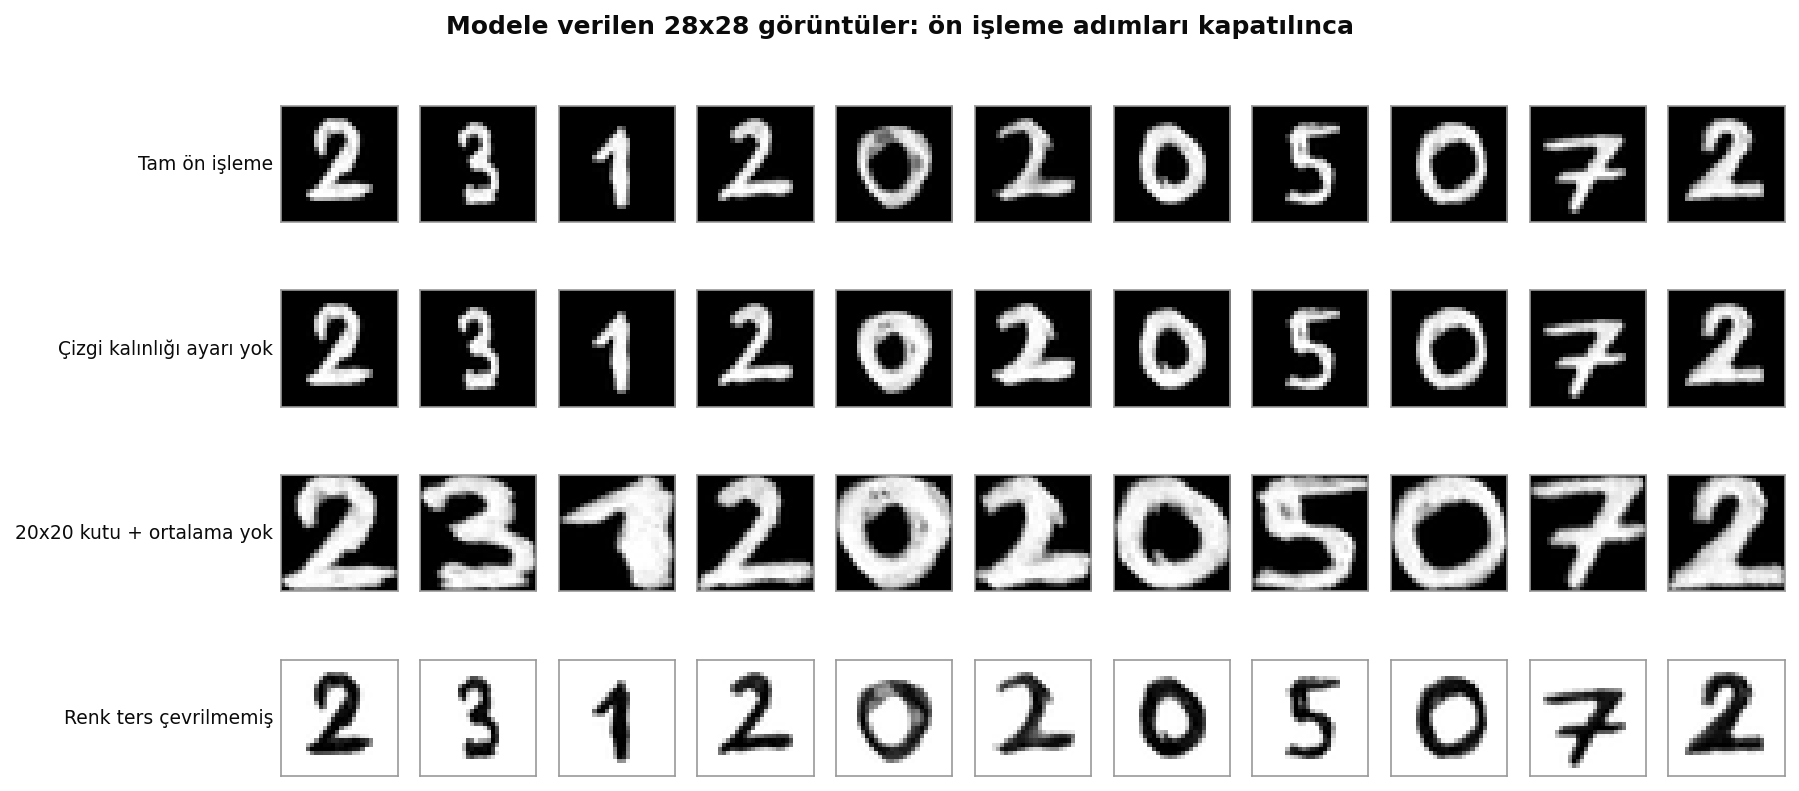

In [14]:
# ===== ÖN İŞLEME KARŞILAŞTIRMASI: distribution shift'in etkisi =====
# Aynı modeller + aynı fotoğraflar, ama ön işleme adımları tek tek kapatılıyor.
# Amaç: modelin başarısının, verinin MNIST formatına ne kadar benzediğine bağlı olduğunu göstermek.

def kalinlik_ayarsiz(crop):
    # Çizgi kalınlığı MNIST'e benzetilmiyor (20x20 kutu ve ortalama var)
    ys, xs = np.nonzero(crop > 0.05)
    c = crop[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = c.shape
    s = 20 / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = np.clip(np.asarray(Image.fromarray(c, "F").resize((nw, nh), Image.LANCZOS)), 0, 1)
    out = np.zeros((28, 28), np.float32)
    out[(28 - nh) // 2:(28 - nh) // 2 + nh, (28 - nw) // 2:(28 - nw) // 2 + nw] = small
    cy, cx = ndimage.center_of_mass(out)
    out = np.roll(out, (int(round(13.5 - cy)), int(round(13.5 - cx))), axis=(0, 1))
    return out / max(out.max(), 1e-6)

def ortalamasiz(crop):
    # 20x20 kutuya sığdırma ve ortalama YOK: kırpılan rakam doğrudan 28x28'e gerdiriliyor
    ys, xs = np.nonzero(crop > 0.05)
    c = crop[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    return np.clip(np.asarray(Image.fromarray(c, "F").resize((28, 28), Image.LANCZOS)), 0, 1)

def ters_cevrilmemis(crop):
    # Renkler ters çevrilmiyor: beyaz zemin üzerine siyah rakam (MNIST'in tersi)
    return 1.0 - to_mnist_28(crop)

varyantlar = {
    "Tam ön işleme": to_mnist_28,
    "Çizgi kalınlığı ayarı yok": kalinlik_ayarsiz,
    "20x20 kutu + ortalama yok": ortalamasiz,
    "Renk ters çevrilmemiş": ters_cevrilmemis,
}

# Her fotoğraftan rakamları ayır (ayırma adımı tüm varyantlarda aynı)
kirpintilar = []
for path in paths:
    gray = load_gray(path)
    ink = ink_map(gray)
    mask, t = ink_mask(ink)
    hi = np.percentile(ink[mask], 90)
    soft = np.clip((ink - 0.5 * t) / max(hi - 0.5 * t, 1e-3), 0, 1)
    boxes, lab = segment_digits(mask, len(OGRENCI_NO))
    for b in boxes[:len(OGRENCI_NO)]:
        sl = (slice(b["y0"], b["y1"]), slice(b["x0"], b["x1"]))
        region = ndimage.binary_dilation(np.isin(lab[sl], b["ids"]), iterations=2)
        kirpintilar.append(np.pad(soft[sl] * region, 4).astype(np.float32))
gercek = np.array([int(c) for c in OGRENCI_NO] * len(paths))[:len(kirpintilar)]

karsilastirma_modelleri = {"Temel (Deney 1)": model1, "En iyi (Deney 2)": models[best_name]}
satirlar, ornekler = [], {}
for ad, fn in varyantlar.items():
    X = np.stack([fn(c) for c in kirpintilar]).astype(np.float32)
    ornekler[ad] = X
    satir = {"Ön işleme": ad}
    for m_ad, m in karsilastirma_modelleri.items():
        with torch.no_grad():
            tahmin = m.eval()(normalize(torch.from_numpy(X), data["mean"], data["std"])).argmax(1).numpy()
        dogru_sayi = int((tahmin == gercek).sum())
        satir[m_ad] = f"{dogru_sayi}/{len(gercek)} (%{100 * dogru_sayi / len(gercek):.0f})"
    satirlar.append(satir)

karsilastirma = pd.DataFrame(satirlar)
karsilastirma.to_csv(f"{OUT}/on_isleme_karsilastirma.csv", index=False)
display(karsilastirma)

# Görsel: aynı rakamların her varyantta modele nasıl göründüğü (ilk fotoğrafın rakamları)
n = min(len(OGRENCI_NO), len(kirpintilar))
fig, axes = plt.subplots(len(varyantlar), n, figsize=(1.1 * n, 1.25 * len(varyantlar) + 0.6))
for i, (ad, X) in enumerate(ornekler.items()):
    for j in range(n):
        axes[i, j].imshow(X[j], cmap="gray", vmin=0, vmax=1)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([]); axes[i, j].grid(False)
        for kenar in axes[i, j].spines.values():
            kenar.set_visible(True); kenar.set_color("#999999")
    axes[i, 0].set_ylabel(ad, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Modele verilen 28x28 görüntüler: ön işleme adımları kapatılınca", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{OUT}/on_isleme_karsilastirma.png")
plt.close(fig)
goster(f"{OUT}/on_isleme_karsilastirma.png")

## 7. Sonuçları indir


In [15]:
import shutil
shutil.copytree("el_yazisi", f"{OUT}/el_yazisi", dirs_exist_ok=True)
shutil.make_archive("sonuclar", "zip", OUT)
try:
    from google.colab import files
    files.download("sonuclar.zip")
except ImportError:
    print("sonuclar.zip oluşturuldu")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Genel değerlendirme

- **Deney 1:** Training loss 0.011'e inerken validation loss 5. epoch'tan sonra 0.082'den 0.111'e yükseldi (overfitting). Test doğruluğu %98.00.
- **Deney 2:** En etkili ayarlar learning rate/optimizer ve düzenlileştirme oldu. Momentumsuz SGD %95.9'da kaldı; dropout + veri artırma en iyi sonucu verdi (test %98.79).
- **Train / validation / test:** Tutarlı. En iyi modelde validation %98.98, test %98.79.
- **Kendi el yazım:** Temel model 33 rakamın 32'sini bildi; hızlı yazdığım yassı "0"ı "9" sandı. En iyi model 33/33. Ön işleme kapatılınca doğruluk %0–61'e düştü: MLP pikselleri tek tek gördüğü için verinin MNIST formatına benzemesi şart (distribution shift).